# Assignment 10 — Adaptive Median Filter and Otsu Thresholding

**Questions:**
1. Write a program to denoise the input image using an **adaptive median filter**. Input the initial window size and the maximum window size $S_{max}$ from the user. Compare the performance of the median filter and the adaptive median filter using PSNR values.
2. Write a program to threshold the image using **Otsu's global threshold** for segmentation of an input grayscale image.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from skimage import data

plt.rcParams['figure.dpi'] = 100


def ask(prompt, default, cast=float):
    """Read a value from the user.
    If the user just presses Enter, types something invalid, or the notebook is
    run non-interactively (no keyboard input possible), the default is used."""
    try:
        text = input(f"{prompt} [default = {default}]: ").strip()
        return cast(text) if text else default
    except Exception:
        print(f"{prompt}: no valid input, using default = {default}")
        return default


def show(images, titles, cols=None, size=4):
    """Display a list of images side by side (grayscale shown on a fixed 0-255 scale)."""
    n = len(images)
    cols = cols or n
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis('off')
    for ax, im, t in zip(axes, images, titles):
        if im.ndim == 2:
            ax.imshow(im, cmap='gray', vmin=0, vmax=1 if im.max() <= 1 else 255)
        else:
            ax.imshow(im)
        ax.set_title(t)
    plt.tight_layout()
    plt.show()

In [2]:
# Input image: set IMAGE_PATH to use your own image, otherwise a standard test image is used.
IMAGE_PATH = None   # e.g. "my_image.jpg"

if IMAGE_PATH:
    img = cv2.imread(IMAGE_PATH, cv2.IMREAD_GRAYSCALE)
else:
    img = data.camera()   # 'cameraman' test image from scikit-image

print("Image size:", img.shape, "| dtype:", img.dtype, "| min/max:", img.min(), img.max())

Image size: (512, 512) | dtype: uint8 | min/max: 0 255


## Part 1 — Adaptive median filter

For each pixel, with $z_{min}, z_{max}, z_{med}$ the min, max and median of the current $S_{xy}$ window and $z_{xy}$ the pixel value:

**Stage A:** if $z_{min} < z_{med} < z_{max}$ go to Stage B. Otherwise increase the window size; if the size is still $\le S_{max}$ repeat Stage A, else output $z_{med}$.

**Stage B:** if $z_{min} < z_{xy} < z_{max}$ output $z_{xy}$ (the pixel is not noise, keep it), else output $z_{med}$.

So the window grows only where it needs to, and pixels that are not noise are left unchanged. This keeps much more detail than a normal median filter. The implementation below processes all pixels at once for each window size.

In [3]:
from scipy.ndimage import minimum_filter, maximum_filter, median_filter
from skimage.util import random_noise


def adaptive_median(image, s_init=3, s_max=7):
    z = image.astype(np.int32)
    out = z.copy()
    done = np.zeros(z.shape, dtype=bool)
    for s in range(s_init, s_max + 1, 2):
        zmin = minimum_filter(z, size=s, mode='reflect')
        zmax = maximum_filter(z, size=s, mode='reflect')
        zmed = median_filter(z, size=s, mode='reflect')
        stage_a = (zmin < zmed) & (zmed < zmax) & ~done          # median is not an impulse
        keep = (zmin < z) & (z < zmax)                            # Stage B test
        out[stage_a] = np.where(keep, z, zmed)[stage_a]
        done |= stage_a
        if done.all():
            break
    out[~done] = zmed[~done]                                     # window reached s_max: output z_med
    return out.astype(np.uint8)


def psnr(original, processed):
    mse = np.mean((original.astype(np.float64) - processed.astype(np.float64)) ** 2)
    return float('inf') if mse == 0 else 10 * np.log10(255 ** 2 / mse)

Enter initial window size (odd): no valid input, using default = 3
Enter maximum window size Smax (odd): no valid input, using default = 7
Enter salt & pepper noise density (0-1): no valid input, using default = 0.3
Using initial window 3x3, Smax = 7, noise density = 0.3


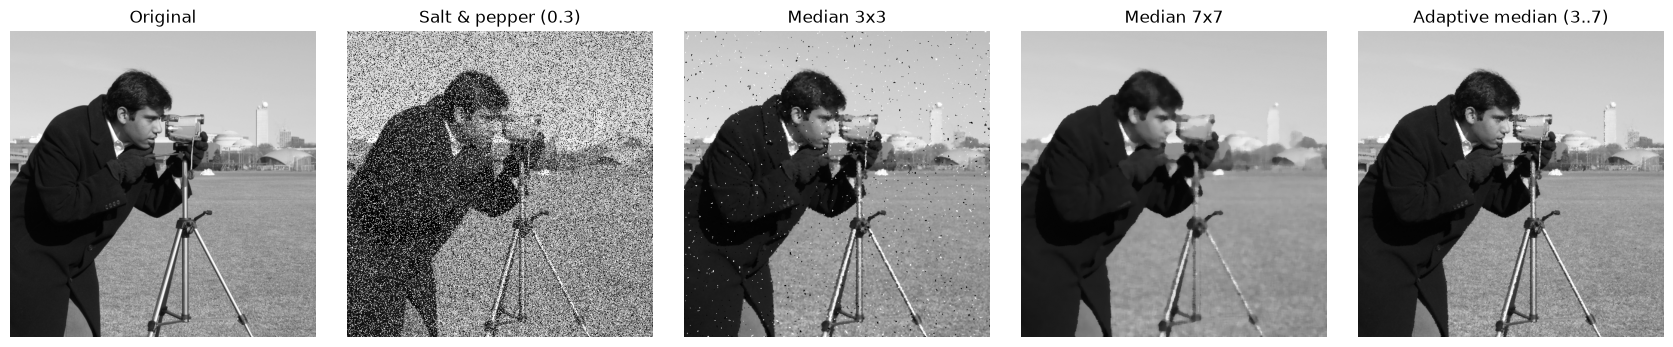

PSNR noisy image      :  10.03 dB
PSNR median 3x3       :  22.81 dB
PSNR median 7x7       :  25.60 dB
PSNR adaptive median  :  30.35 dB


In [4]:
s_init = ask("Enter initial window size (odd)", 3, int)
s_max = ask("Enter maximum window size Smax (odd)", 7, int)
density = ask("Enter salt & pepper noise density (0-1)", 0.3)
if s_init < 3 or s_init % 2 == 0: s_init = 3
if s_max < s_init or s_max % 2 == 0: s_max = max(s_init, s_max + (s_max % 2 == 0))
print(f"Using initial window {s_init}x{s_init}, Smax = {s_max}, noise density = {density}")

noisy = (random_noise(img, mode='s&p', amount=density, rng=0) * 255).astype(np.uint8)
med3 = cv2.medianBlur(noisy, 3)
med_s = cv2.medianBlur(noisy, s_max)
amf = adaptive_median(noisy, s_init, s_max)

show([img, noisy, med3, med_s, amf],
     ['Original', f'Salt & pepper ({density})', 'Median 3x3', f'Median {s_max}x{s_max}', f'Adaptive median ({s_init}..{s_max})'],
     cols=5, size=3.4)

print(f"PSNR noisy image      : {psnr(img, noisy):6.2f} dB")
print(f"PSNR median 3x3       : {psnr(img, med3):6.2f} dB")
print(f"PSNR median {s_max}x{s_max}       : {psnr(img, med_s):6.2f} dB")
print(f"PSNR adaptive median  : {psnr(img, amf):6.2f} dB")

### PSNR for different noise densities

 density    noisy  median3  median5  adaptive
    0.05    17.75    30.14    27.84     33.59
    0.10    14.77    29.55    27.69     33.23
    0.20    11.73    26.76    27.14     31.80
    0.30     9.97    22.41    26.54     30.28
    0.40     8.72    18.04    25.38     28.81
    0.50     7.76    14.54    22.60     27.39


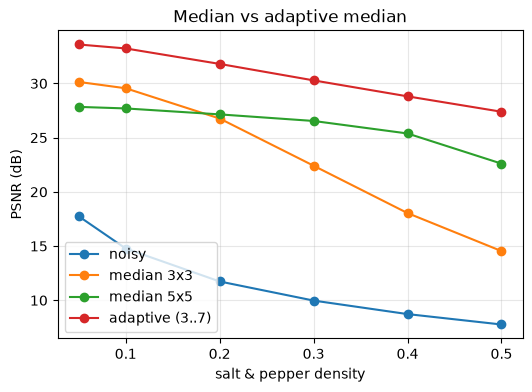

In [5]:
densities = [0.05, 0.1, 0.2, 0.3, 0.4, 0.5]
rows = []
for d in densities:
    nz = (random_noise(img, mode='s&p', amount=d, rng=1) * 255).astype(np.uint8)
    rows.append([psnr(img, nz), psnr(img, cv2.medianBlur(nz, 3)), psnr(img, cv2.medianBlur(nz, 5)),
                 psnr(img, adaptive_median(nz, s_init, s_max))])
rows = np.array(rows)

print(f"{'density':>8}{'noisy':>9}{'median3':>9}{'median5':>9}{'adaptive':>10}")
for d, r in zip(densities, rows):
    print(f"{d:>8.2f}" + ''.join(f"{v:>9.2f}" for v in r[:3]) + f"{r[3]:>10.2f}")

plt.figure(figsize=(6, 4))
for i, lbl in enumerate(['noisy', 'median 3x3', 'median 5x5', f'adaptive ({s_init}..{s_max})']):
    plt.plot(densities, rows[:, i], 'o-', label=lbl)
plt.xlabel('salt & pepper density'); plt.ylabel('PSNR (dB)'); plt.title('Median vs adaptive median')
plt.legend(); plt.grid(alpha=0.3); plt.show()

**Observations:** The normal median filter works for low noise density, but at high density a 3×3 window leaves many impulses, and a larger window blurs the whole image. The adaptive median filter grows the window only around noisy pixels and leaves clean pixels unchanged, so it gets a clearly higher PSNR, and the gap widens as the noise density increases.

## Part 2 — Otsu's global thresholding

Otsu picks the threshold $k$ that maximises the **between-class variance**:
$$ \sigma_B^2(k) = \frac{\left[\mu_T\, \omega(k) - \mu(k)\right]^2}{\omega(k)\,[1-\omega(k)]} $$
where $\omega(k) = \sum_{i=0}^{k} p_i$ is the cumulative probability, $\mu(k) = \sum_{i=0}^{k} i\, p_i$ is the cumulative mean, and $\mu_T$ is the global mean.

Otsu threshold (mine) = 107, separability eta = 0.756
OpenCV Otsu threshold = 107 | skimage threshold_otsu = 107


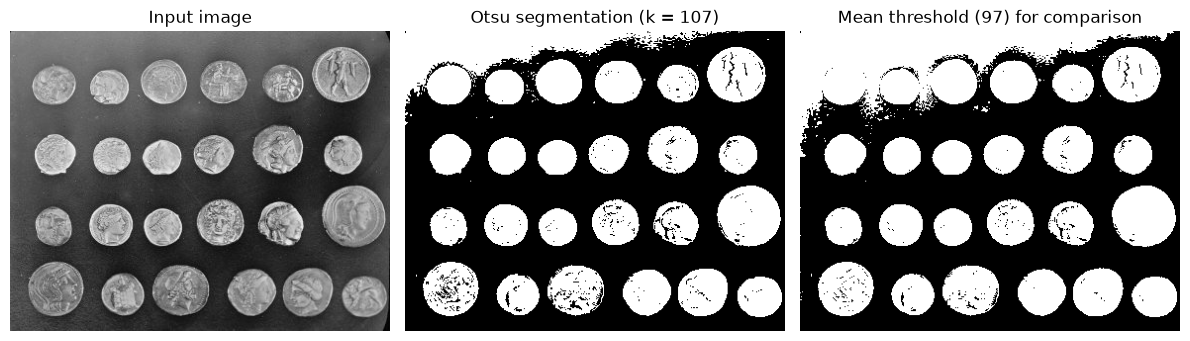

In [6]:
SEG_PATH = None   # optionally use your own image
seg_img = cv2.imread(SEG_PATH, cv2.IMREAD_GRAYSCALE) if SEG_PATH else data.coins()


def otsu_threshold(image):
    p = np.bincount(image.ravel(), minlength=256) / image.size
    omega = np.cumsum(p)
    mu = np.cumsum(np.arange(256) * p)
    mu_t = mu[-1]
    with np.errstate(divide='ignore', invalid='ignore'):
        sigma_b2 = (mu_t * omega - mu) ** 2 / (omega * (1 - omega))
    sigma_b2 = np.nan_to_num(sigma_b2)
    k = int(np.argmax(sigma_b2))
    eta = sigma_b2[k] / np.sum(((np.arange(256) - mu_t) ** 2) * p)   # separability measure (0..1)
    return k, sigma_b2, eta


k_otsu, sigma_b2, eta = otsu_threshold(seg_img)
segmented = (seg_img > k_otsu).astype(np.uint8)
print(f"Otsu threshold (mine) = {k_otsu}, separability eta = {eta:.3f}")

from skimage.filters import threshold_otsu
k_cv, _ = cv2.threshold(seg_img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print(f"OpenCV Otsu threshold = {k_cv:.0f} | skimage threshold_otsu = {threshold_otsu(seg_img)}")

show([seg_img, segmented, (seg_img > seg_img.mean()).astype(np.uint8)],
     ['Input image', f'Otsu segmentation (k = {k_otsu})', f'Mean threshold ({seg_img.mean():.0f}) for comparison'])

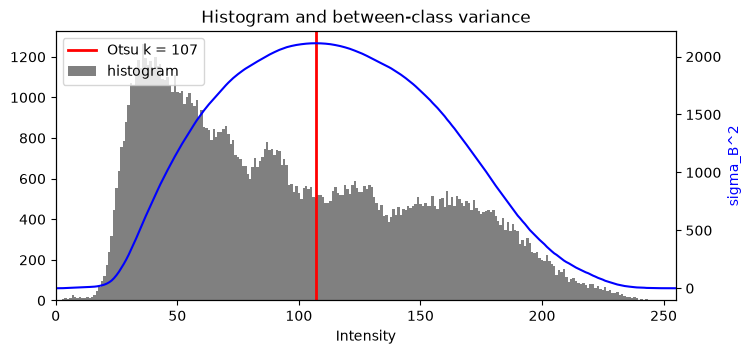

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(np.arange(256), np.bincount(seg_img.ravel(), minlength=256), width=1, color='gray', label='histogram')
ax.axvline(k_otsu, color='r', lw=2, label=f'Otsu k = {k_otsu}')
ax2 = ax.twinx(); ax2.plot(sigma_b2, 'b', label='between-class variance'); ax2.set_ylabel('sigma_B^2', color='b')
ax.set_xlim(0, 255); ax.set_xlabel('Intensity'); ax.set_title('Histogram and between-class variance')
ax.legend(loc='upper left'); plt.show()

**Observations:** Otsu's method needs no user input. It looks at the histogram and picks the threshold that best separates the two classes (coins and background). My implementation gives the same threshold as OpenCV and scikit-image, and it separates the coins from the background better than the simple mean threshold.